# Libraries

In [1]:
import sklearn as sk
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans, AgglomerativeClustering

from sklearn.metrics import silhouette_score

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Global variables

In [2]:
target = "Diabetes_012"

# Helper Function

In [3]:
def divider():
    print("\n\n--------------------------------------------------------------------\n\n")

# Dataset Loading and Audit

No.of Rows: 236378
No.of Columns: 22


--------------------------------------------------------------------


Data types of columns:
Diabetes_012            float64
HighBP                    int64
HighChol                float64
CholCheck                 int64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity              int64
Fruits                    int64
Veggies                   int64
HvyAlcoholConsump         int64
AnyHealthcare             int64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                       int64
Age                       int64
Education               float64
Income                  float64
dtype: object


--------------------------------------------------------------------


No.of null values per column:
Diabetes_012            0
HighBP              

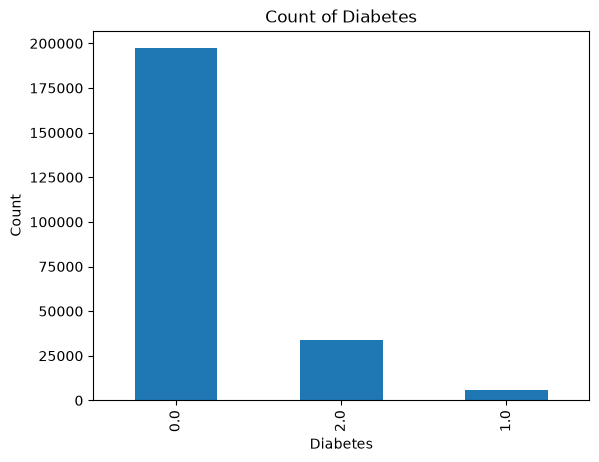

In [4]:
df = pd.read_csv("../data/diabetes_012_health_indicators_BRFSS2021.csv")
print(f"No.of Rows: {df.shape[0]}")
print(f"No.of Columns: {df.shape[1]}")
divider()
print("Data types of columns:")
print(df.dtypes)
divider()
print("No.of null values per column:")
print(df.isna().sum())
divider()

df["Diabetes_012"].value_counts().plot(kind="bar")
print("0: No diabetes\n1: Pre-diabetes\n2: Diabetes")
plt.xlabel("Diabetes")
plt.ylabel("Count")
plt.title("Count of Diabetes")
plt.show()

# EDA

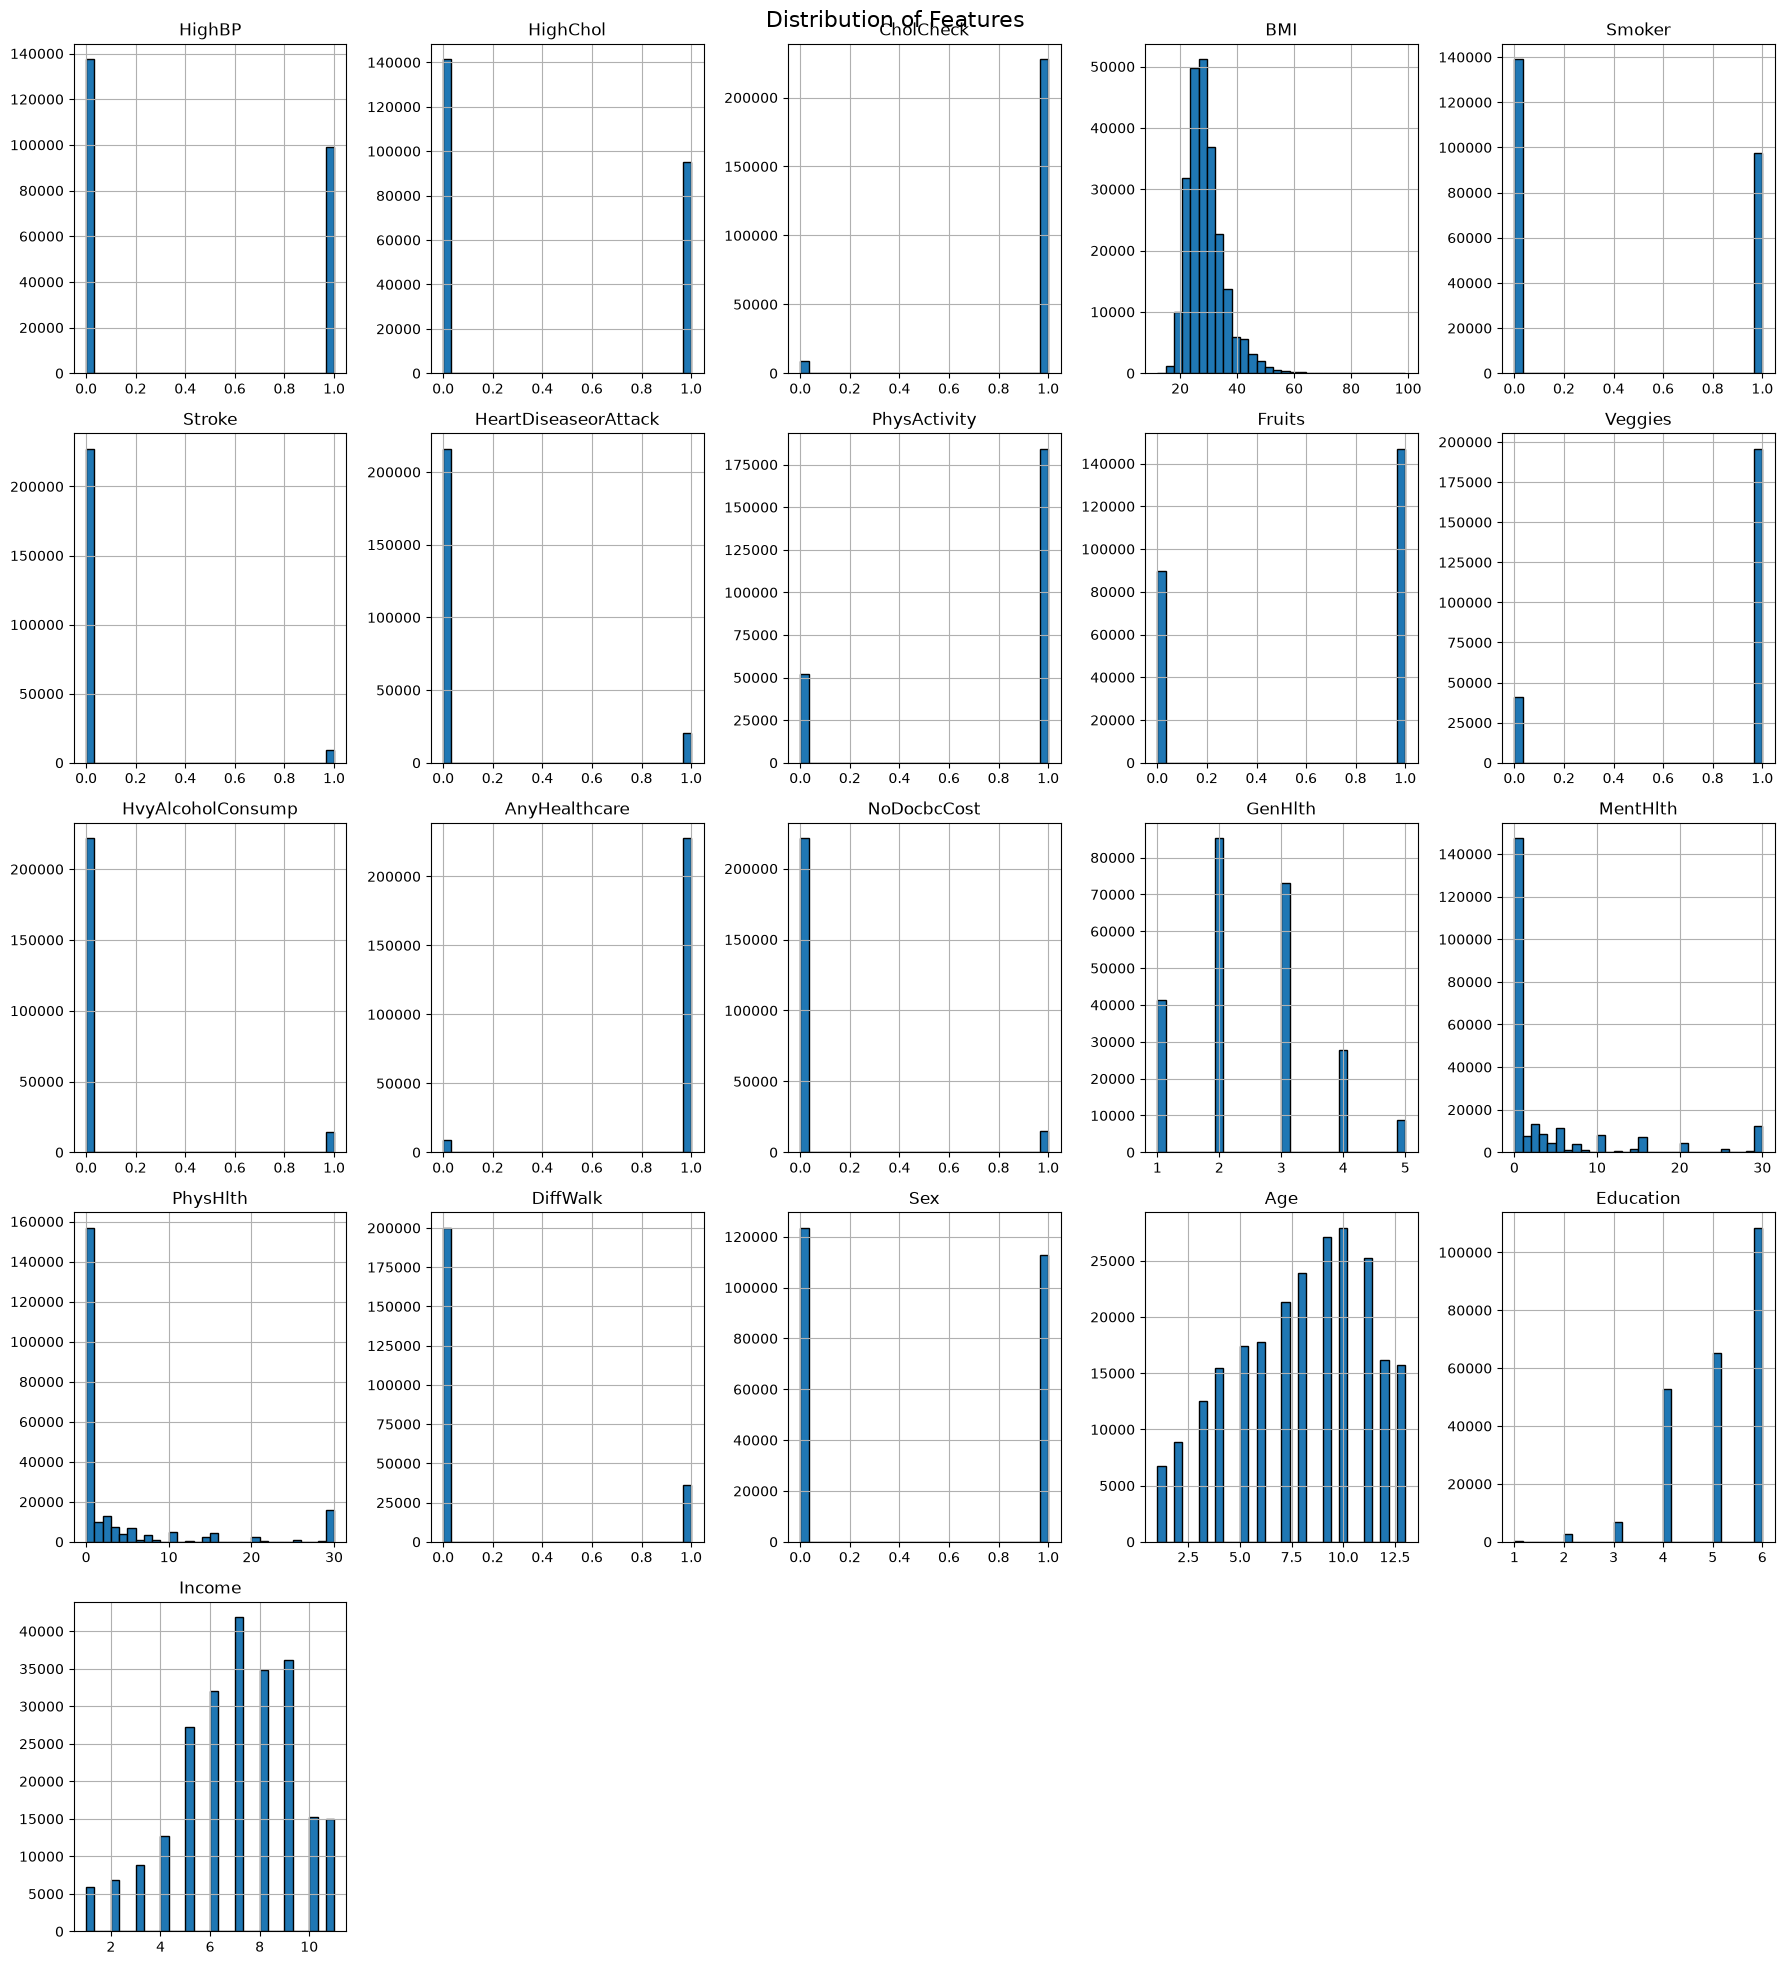



--------------------------------------------------------------------




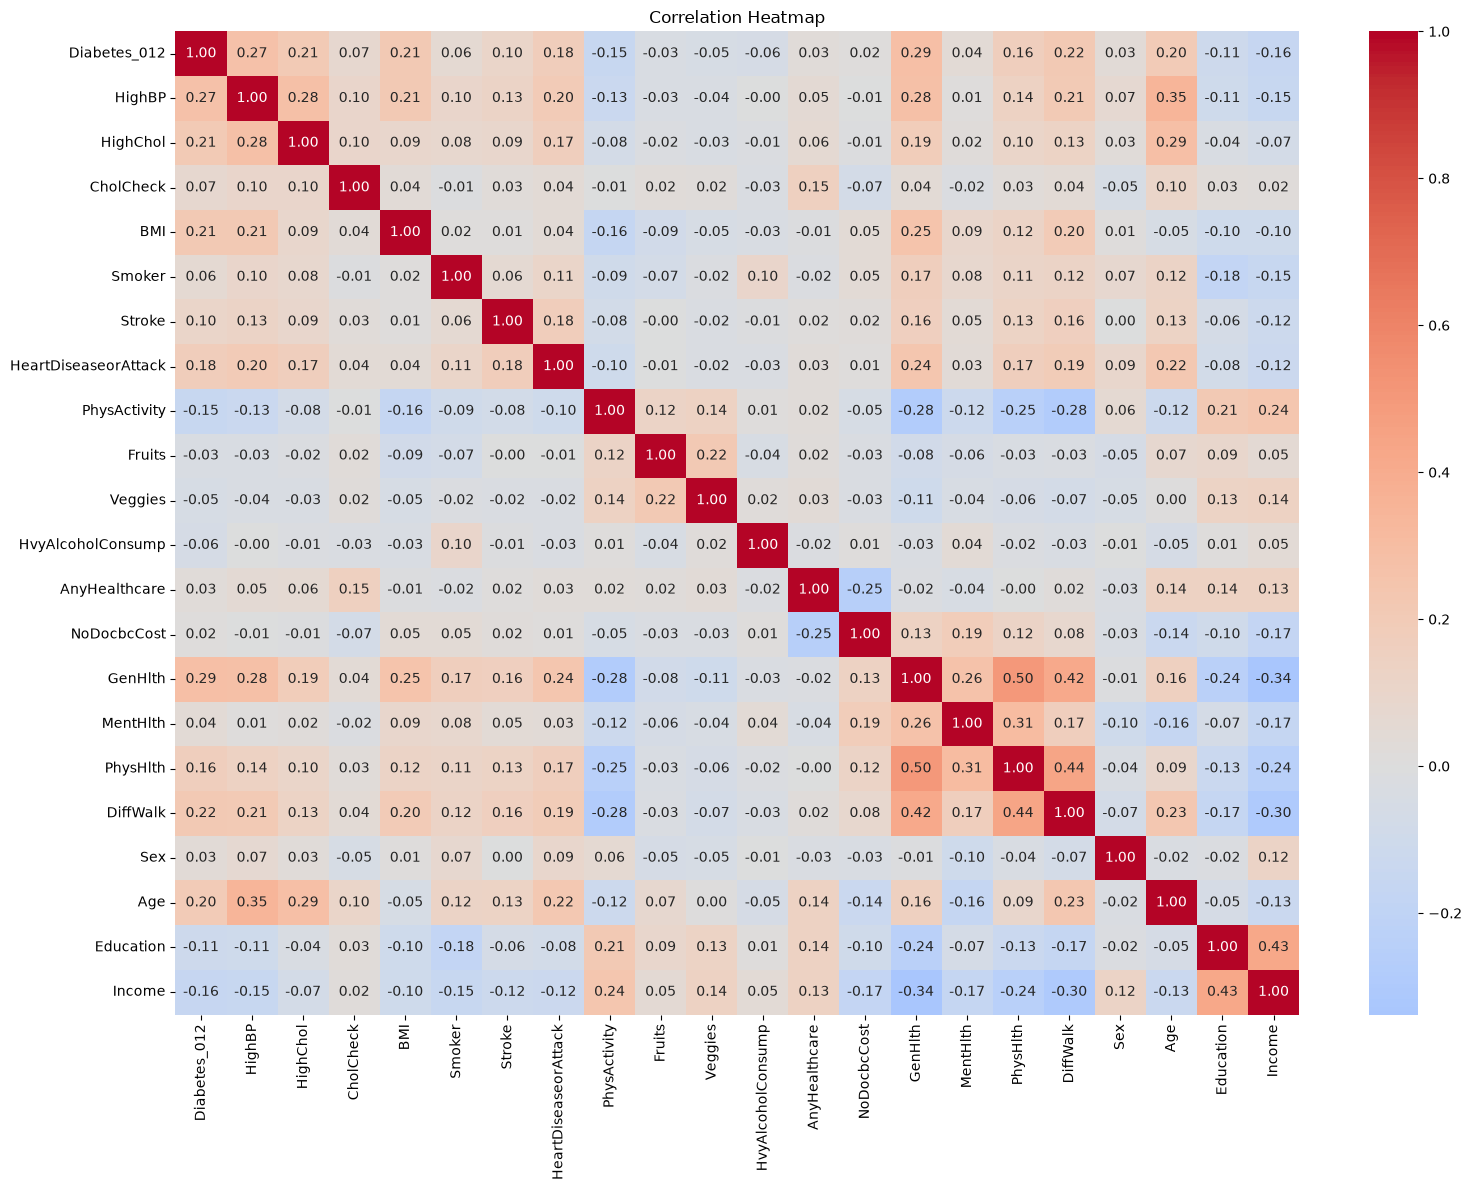



--------------------------------------------------------------------




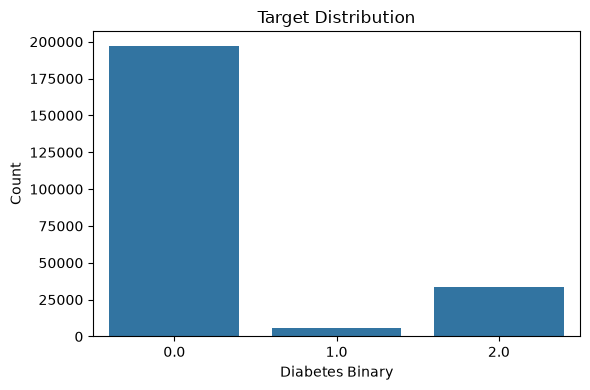



--------------------------------------------------------------------




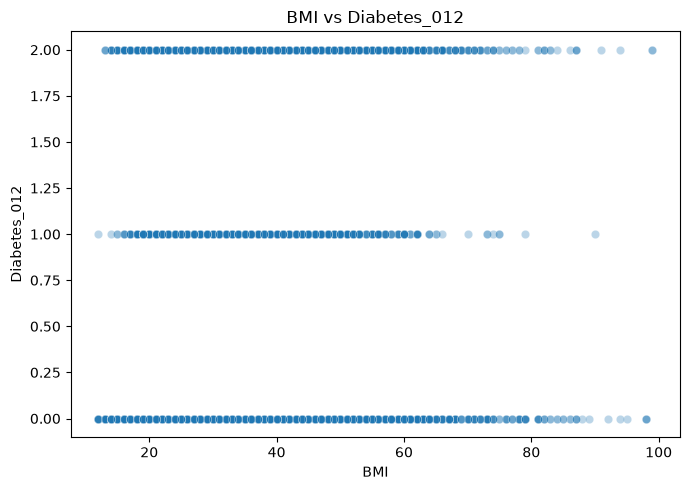

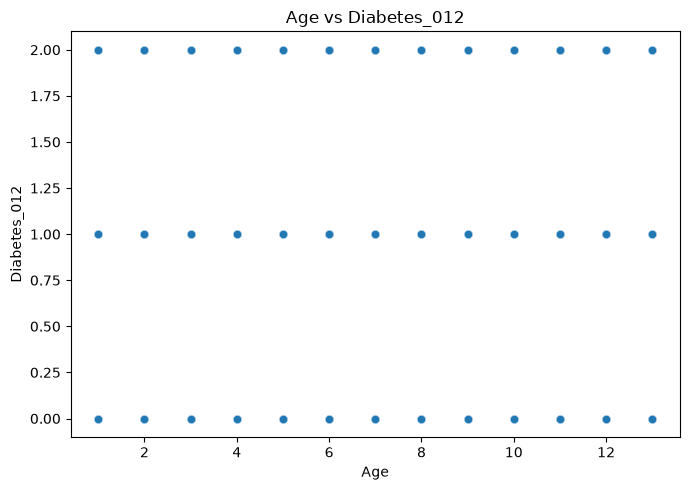

In [5]:
X = df.drop(columns=[target])
y = df[target]


# --------------------------------------------------
# 1. Distribution plots for each feature
# --------------------------------------------------

X.hist(
    bins=30,
    figsize=(18, 20),
    edgecolor="black"
)

plt.suptitle("Distribution of Features", fontsize=16)
plt.tight_layout()
plt.show()
divider()

# --------------------------------------------------
# 2. Correlation heatmap
# --------------------------------------------------

plt.figure(figsize=(16, 12))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
divider()

# --------------------------------------------------
# 3. Target distribution
# --------------------------------------------------

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x=target
)

plt.title("Target Distribution")
plt.xlabel("Diabetes Binary")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
divider()

# --------------------------------------------------
# 4. Feature-target scatter plots
# --------------------------------------------------

feature1 = "BMI"
feature2 = "Age"

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x=feature1,
    y=target,
    alpha=0.3
)

plt.title(f"{feature1} vs {target}")
plt.xlabel(feature1)
plt.ylabel(target)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x=feature2,
    y=target,
    alpha=0.3
)

plt.title(f"{feature2} vs {target}")
plt.xlabel(feature2)
plt.ylabel(target)
plt.tight_layout()
plt.show()

### Interpretation
- The first thing we can see is that the target variable is completely unbalanced.
- Most features are not correlated.
- Some features kinda follow a skewed normal distribution.

# Data cleaning

In [6]:

print("Missing values:")
# Check missing values in each column
print(df.isnull().sum())
divider()

print("Percentage of missing values:")
# Check percentage of missing values
print(df.isnull().mean() * 100)
divider()


# Handle missing values
for col in df.columns:
    if df[col].dtype in ["int64", "float64"]:
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])


print("After handling missing values:")
print(df.isnull().sum())
divider()

# Count duplicate rows
print("Duplicate rows count:", df.duplicated().sum())
divider()

print("Duplicated rows:")
# Display duplicate rows
print(df[df.duplicated()])
divider()

# Remove duplicate rows, keeping the first occurrence
df = df.drop_duplicates()

print("Duplicates after removal:", df.duplicated().sum())

"""
divider()
print("Target distribution after balancing:")
min_count = df[target].value_counts().min()

df = (
    df.groupby(target)
      .sample(n=min_count, random_state=42)
      .reset_index(drop=True)
)
print(df[target].value_counts())
"""

Missing values:
Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


--------------------------------------------------------------------


Percentage of missing values:
Diabetes_012            0.0
HighBP                  0.0
HighChol                0.0
CholCheck               0.0
BMI                     0.0
Smoker                  0.0
Stroke                  0.0
HeartDiseaseorAttack    0.0
PhysActivity            0.0
Fruits                  0.0
Veggies         

'\ndivider()\nprint("Target distribution after balancing:")\nmin_count = df[target].value_counts().min()\n\ndf = (\n    df.groupby(target)\n      .sample(n=min_count, random_state=42)\n      .reset_index(drop=True)\n)\nprint(df[target].value_counts())\n'

# Encoding, scaling & splitting

In [7]:
# Separate features and known labels
X = df.drop(columns=[target])
y = df[target]  # Used only for evaluation

# 2. Identify numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

# 3. train/test split
X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Preprocessing
# Scale numerical features and one-hot encode categoricals
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

# Fit only on training features
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform test features using training-fitted parameters
X_test_scaled = preprocessor.transform(X_test)


Numerical columns: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Categorical columns: []


# Feature engineering

In [8]:
# 5. Remove highly correlated features
import numpy as np
import pandas as pd
from scipy.sparse import issparse

# Convert to dense arrays for correlation calculation
X_train_dense = (
    X_train_scaled.toarray()
    if issparse(X_train_scaled)
    else X_train_scaled
)

X_test_dense = (
    X_test_scaled.toarray()
    if issparse(X_test_scaled)
    else X_test_scaled
)

# Calculate correlation matrix using training data only
corr_matrix = pd.DataFrame(X_train_dense).corr().abs()

# Get upper triangle of correlation matrix
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Identify features with correlation above 0.90
threshold = 0.90
to_drop = [
    column
    for column in upper.columns
    if any(upper[column] > threshold)
]

# Keep the same columns in both datasets
keep_cols = [
    i for i in range(X_train_dense.shape[1])
    if i not in to_drop
]

X_train_scaled = X_train_dense[:, keep_cols]
X_test_scaled = X_test_dense[:, keep_cols]

print("Original number of features:", len(num_cols) + len(cat_cols))
print("Features removed:", len(to_drop))
print("Features remaining:", X_train_scaled.shape[1])
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

X = X_train_scaled
X_test = X_test_scaled

Original number of features: 21
Features removed: 0
Features remaining: 21
Training shape: (178840, 21)
Testing shape: (44710, 21)


# K-Means Clustering

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# ==========================================
# 1. PREPARE DATA
# ==========================================
X_array = X.to_numpy() if hasattr(X, "to_numpy") else np.asarray(X)
X_array = np.asarray(X_array, dtype=np.float64)

if not np.isfinite(X_array).all():
    raise ValueError("Clean missing and infinite values in X first.")

if len(X_array) < 3:
    raise ValueError("At least 3 observations are required.")

rng = np.random.default_rng(42)
sample_size = min(20000, len(X_array))
sample_idx = np.sort(
    rng.choice(len(X_array), sample_size, replace=False)
)
X_compare = X_array[sample_idx]

# ==========================================
# 2. ELBOW CURVE + ALL THREE METRICS
# ==========================================
k_values = list(range(2, min(11, len(X_array))))
inertias = []
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit K-Means on the full dataset
    labels = model.fit_predict(X_array)

    inertias.append(model.inertia_)

    # Evaluate on the same fixed sample for every k
    sample_labels_k = labels[sample_idx]

    silhouette_scores.append(
        silhouette_score(X_compare, sample_labels_k)
    )

    davies_bouldin_scores.append(
        davies_bouldin_score(X_compare, sample_labels_k)
    )

    calinski_harabasz_scores.append(
        calinski_harabasz_score(X_compare, sample_labels_k)
    )

# Combine results into a table
k_results = pd.DataFrame({
    "k": k_values,
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores,
    "Davies-Bouldin Index": davies_bouldin_scores,
    "Calinski-Harabasz Index": calinski_harabasz_scores
})

print("\nK-Means Results for Different Values of k")
print(k_results.round(4).to_string(index=False))

# ==========================================
# 3. PLOT ELBOW AND THREE METRICS
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elbow curve
axes[0, 0].plot(k_values, inertias, marker="o")
axes[0, 0].set_title("K-Means Elbow Curve")
axes[0, 0].set_xlabel("Number of Clusters (k)")
axes[0, 0].set_ylabel("Inertia (WCSS)")
axes[0, 0].set_xticks(k_values)
axes[0, 0].grid(True, alpha=0.3)

# Silhouette Score: higher is better
axes[0, 1].plot(
    k_values, silhouette_scores, marker="o"
)
axes[0, 1].set_title("Silhouette Score vs k")
axes[0, 1].set_xlabel("Number of Clusters (k)")
axes[0, 1].set_ylabel("Silhouette Score")
axes[0, 1].set_xticks(k_values)
axes[0, 1].grid(True, alpha=0.3)

# Davies-Bouldin Index: lower is better
axes[1, 0].plot(
    k_values, davies_bouldin_scores, marker="o"
)
axes[1, 0].set_title("Davies-Bouldin Index vs k")
axes[1, 0].set_xlabel("Number of Clusters (k)")
axes[1, 0].set_ylabel("Davies-Bouldin Index")
axes[1, 0].set_xticks(k_values)
axes[1, 0].grid(True, alpha=0.3)

# Calinski-Harabasz Index: higher is better
axes[1, 1].plot(
    k_values, calinski_harabasz_scores, marker="o"
)
axes[1, 1].set_title("Calinski-Harabasz Index vs k")
axes[1, 1].set_xlabel("Number of Clusters (k)")
axes[1, 1].set_ylabel("Calinski-Harabasz Index")
axes[1, 1].set_xticks(k_values)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# 4. SELECT k AND FIT FINAL K-MEANS
# ==========================================
# Choose after inspecting the elbow and metrics
chosen_k = 3

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_array)
sample_labels = kmeans_labels[sample_idx]

print("\nChosen k:", chosen_k)
print("Cluster labels:", np.unique(kmeans_labels))
print("Cluster sizes:", np.bincount(kmeans_labels))
print("Full-data inertia:", round(kmeans.inertia_, 4))

# ==========================================
# 5. FINAL EVALUATION METRICS
# ==========================================
final_metrics = {
    "Silhouette Score": silhouette_score(
        X_compare, sample_labels
    ),
    "Davies-Bouldin Index": davies_bouldin_score(
        X_compare, sample_labels
    ),
    "Calinski-Harabasz Index": calinski_harabasz_score(
        X_compare, sample_labels
    )
}

metrics_df = pd.DataFrame(
    list(final_metrics.items()),
    columns=["Metric", "Score"]
)

print("\nFinal K-Means Evaluation Metrics")
print(metrics_df.round(4).to_string(index=False))

# ==========================================
# 6. PLOT FINAL METRICS SEPARATELY
# ==========================================
# Separate plots prevent the different score scales
# from making one metric unreadable.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metric_info = [
    ("Silhouette Score", "Higher is better"),
    ("Davies-Bouldin Index", "Lower is better"),
    ("Calinski-Harabasz Index", "Higher is better")
]

for ax, (metric, direction) in zip(axes, metric_info):
    value = final_metrics[metric]

    ax.bar([metric], [value])
    ax.set_title(f"{metric}\n({direction})")
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="y", alpha=0.3)

    # Label the bar with its value
    ax.bar_label(
        ax.containers[0],
        fmt="%.4f",
        padding=3
    )

plt.tight_layout()
plt.show()

# ==========================================
# 7. CLUSTER SIZE VISUALIZATION
# ==========================================
cluster_ids, cluster_counts = np.unique(
    kmeans_labels, return_counts=True
)

plt.figure(figsize=(8, 5))
plt.bar(cluster_ids, cluster_counts)
plt.xlabel("Cluster")
plt.ylabel("Number of Observations")
plt.title("K-Means Cluster Sizes")
plt.xticks(cluster_ids)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 8. PCA 2D VISUALIZATION
# ==========================================
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_compare)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=sample_labels,
    cmap="viridis",
    s=12,
    alpha=0.7
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters — PCA 2D")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "PCA variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ==========================================
# 9. t-SNE VISUALIZATION
# ==========================================
tsne = TSNE(
    n_components=2,
    perplexity=min(30, (len(X_compare) - 1) / 3),
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_compare)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=sample_labels,
    cmap="viridis",
    s=12,
    alpha=0.7
)
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("K-Means Clusters — t-SNE")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()


# Agglomerative Hierarchical Clustering


Linkage: single
Cluster labels: [0 1 2]
Cluster sizes: [19998     1     1]

Linkage: complete
Cluster labels: [0 1 2]
Cluster sizes: [18709   140  1151]

Linkage: average
Cluster labels: [0 1 2]
Cluster sizes: [19997     2     1]

Linkage: ward
Cluster labels: [0 1 2]
Cluster sizes: [ 4523 13732  1745]

AGGLOMERATIVE CLUSTERING METRICS
               Algorithm  Clusters  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
  Agglomerative - single         3            0.4862                0.3635                   7.2979
Agglomerative - complete         3            0.2212                2.0975                 586.5302
 Agglomerative - average         3            0.4978                0.5850                  10.1434
    Agglomerative - ward         3            0.1632                2.6409                1535.5528


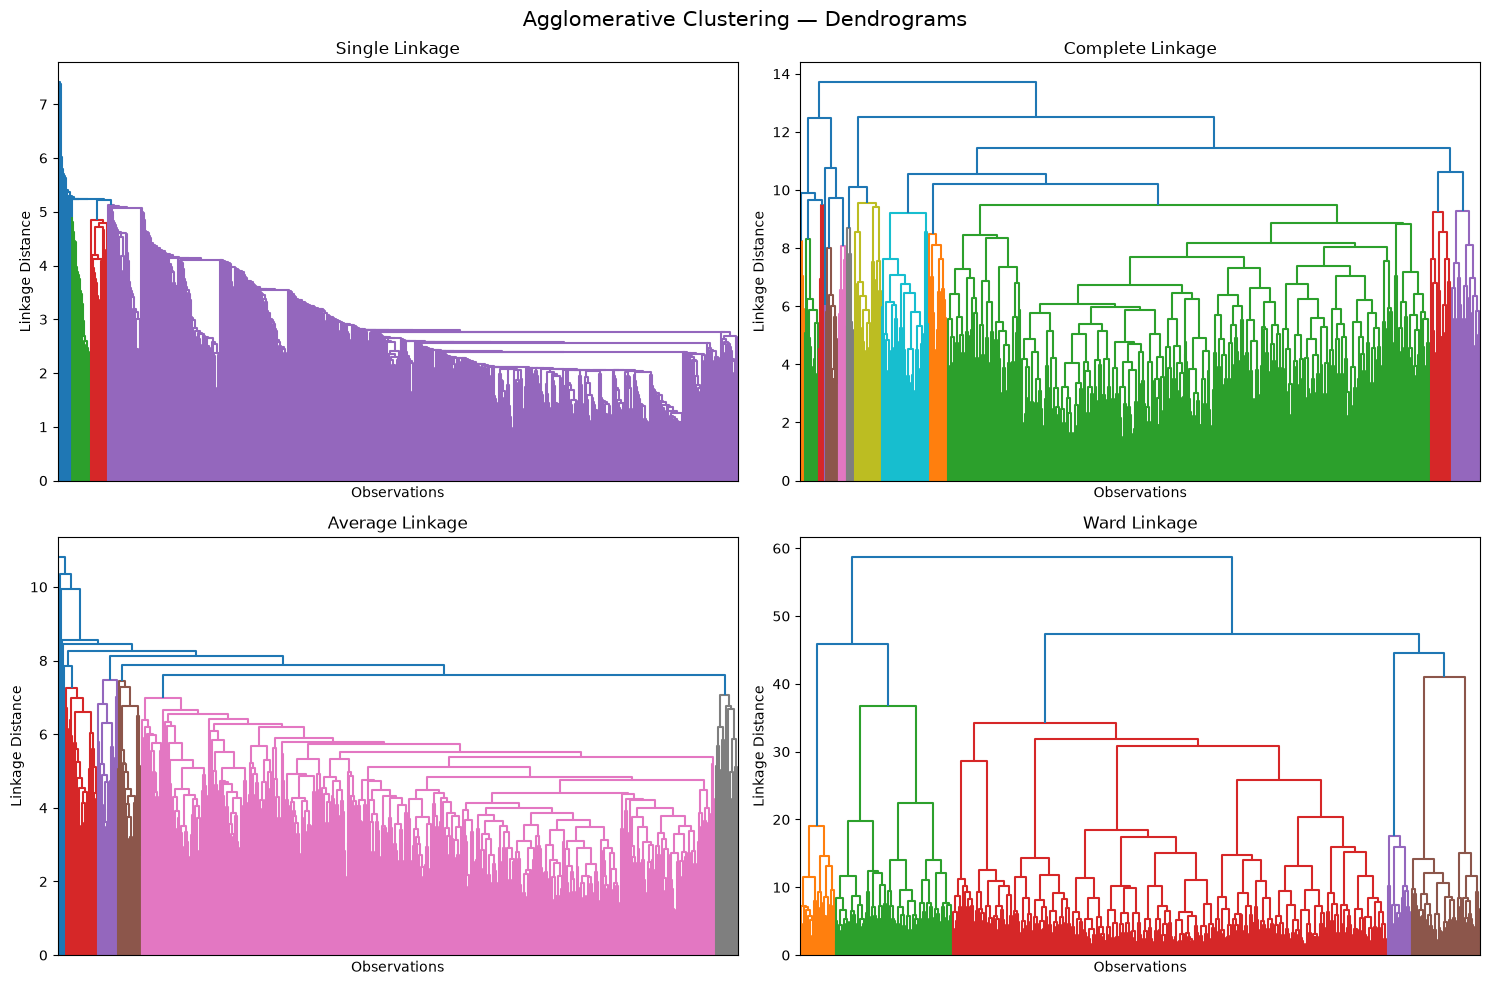

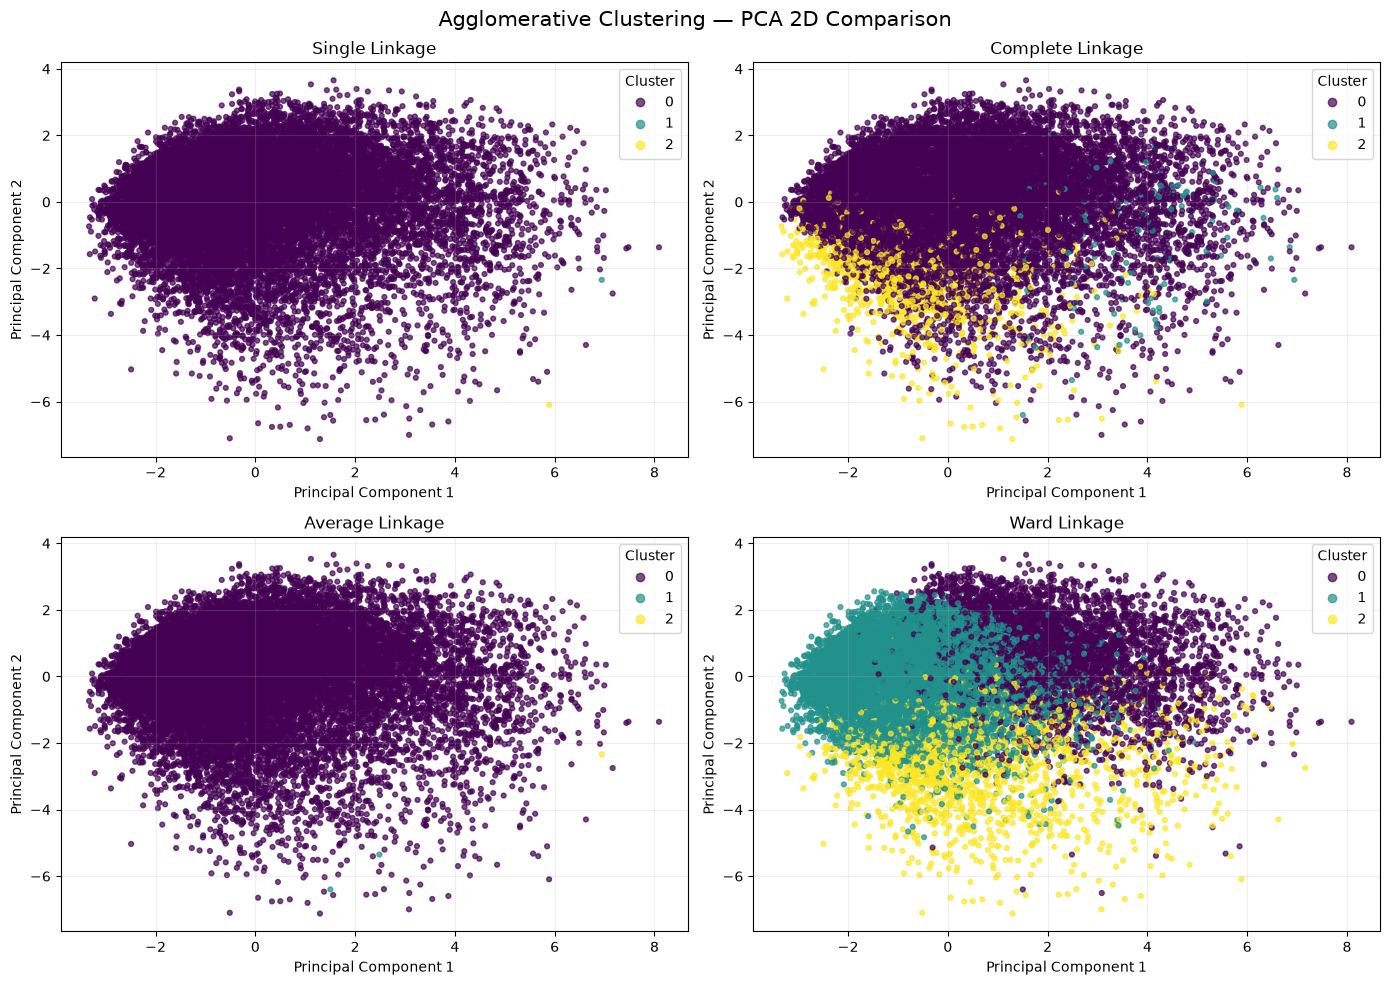

PCA variance explained: 24.06 %


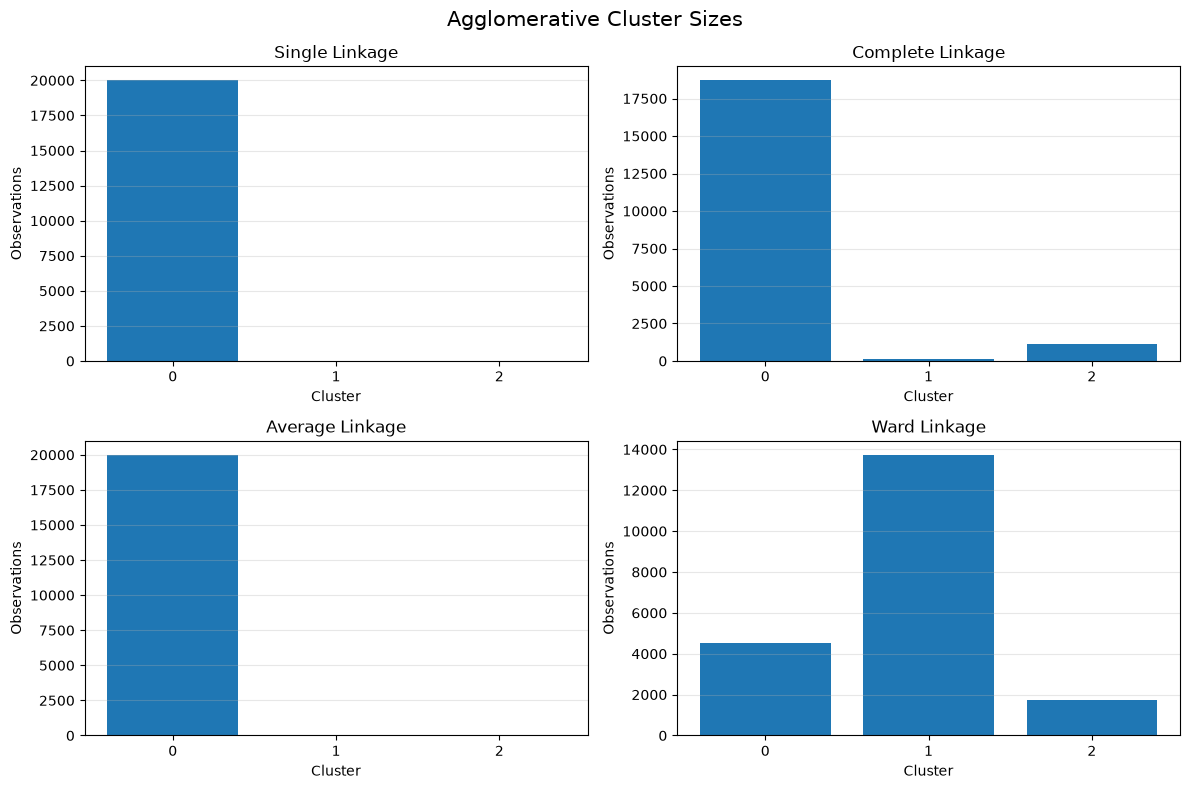

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.cluster.hierarchy import linkage, dendrogram

# ==========================================
# 1. PREPARE THE SAME COMPARISON SAMPLE
# ==========================================
X_array = X.to_numpy() if hasattr(X, "to_numpy") else np.asarray(X)
X_array = np.asarray(X_array, dtype=np.float64)

if not np.isfinite(X_array).all():
    raise ValueError("Clean missing and infinite values in X first.")

rng = np.random.default_rng(42)
sample_size = min(20000, len(X_array))
sample_idx = np.sort(
    rng.choice(len(X_array), sample_size, replace=False)
)
X_compare = X_array[sample_idx]

chosen_k = 3
linkage_methods = ["single", "complete", "average", "ward"]

# ==========================================
# 2. FIT AGGLOMERATIVE MODELS
# ==========================================
agg_labels = {}
results = []

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=chosen_k,
        linkage=method,
        metric="euclidean"
    )

    labels = model.fit_predict(X_compare)
    agg_labels[method] = labels

    n_clusters = len(np.unique(labels))

    print(f"\nLinkage: {method}")
    print("Cluster labels:", np.unique(labels))
    print("Cluster sizes:", np.bincount(labels))

    if 1 < n_clusters < len(X_compare):
        results.append({
            "Algorithm": f"Agglomerative - {method}",
            "Clusters": n_clusters,
            "Silhouette Score": silhouette_score(
                X_compare, labels
            ),
            "Davies-Bouldin Index": davies_bouldin_score(
                X_compare, labels
            ),
            "Calinski-Harabasz Index": calinski_harabasz_score(
                X_compare, labels
            )
        })
    else:
        print("Metrics skipped: invalid number of clusters.")

# ==========================================
# 3. EVALUATION METRICS TABLE
# ==========================================
agg_metrics = pd.DataFrame(results)

print("\nAGGLOMERATIVE CLUSTERING METRICS")
print(agg_metrics.round(4).to_string(index=False))

# ==========================================
# 4. DENDROGRAMS
# ==========================================
dendrogram_rows = min(1000, len(X_array))
dendrogram_idx = np.sort(
    rng.choice(len(X_array), dendrogram_rows, replace=False)
)
X_dendro = X_array[dendrogram_idx]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

for ax, method in zip(axes, linkage_methods):
    Z = linkage(
        X_dendro,
        method=method,
        metric="euclidean"
    )

    dendrogram(
        Z,
        ax=ax,
        no_labels=True
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Observations")
    ax.set_ylabel("Linkage Distance")

fig.suptitle(
    "Agglomerative Clustering — Dendrograms",
    fontsize=15
)
plt.tight_layout()
plt.show()

# ==========================================
# 5. PCA 2D VISUALISATION FOR ALL LINKAGES
# ==========================================
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_compare)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, method in zip(axes, linkage_methods):
    labels = agg_labels[method]

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=12,
        alpha=0.7
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(*scatter.legend_elements(), title="Cluster")
    ax.grid(True, alpha=0.2)

fig.suptitle(
    "Agglomerative Clustering — PCA 2D Comparison",
    fontsize=15
)
plt.tight_layout()
plt.show()

print(
    "PCA variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ==========================================
# 6. CLUSTER SIZE COMPARISON
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, method in zip(axes, linkage_methods):
    cluster_ids, counts = np.unique(
        agg_labels[method], return_counts=True
    )

    ax.bar(cluster_ids, counts)
    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Observations")
    ax.set_xticks(cluster_ids)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Agglomerative Cluster Sizes", fontsize=15)
plt.tight_layout()
plt.show()
